In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline
import matplotlib
matplotlib.rcParams["figure.figsize"] = (20,10)

In [2]:
df1 = pd.read_csv("Bengaluru_House_Data.csv")   # adjust path if needed
print(df1.shape)
df1.head()

(13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
df1.columns = df1.columns.str.strip().str.lower().str.replace(' ', '_')
print(df1.columns)

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')


In [4]:
print(df1['area_type'].unique())
print(df1['area_type'].value_counts())

['Super built-up  Area' 'Plot  Area' 'Built-up  Area' 'Carpet  Area']
area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64


In [5]:
df2 = df1.drop(['area_type', 'society', 'balcony', 'availability'], axis='columns')
print(df2.shape)
df2.isnull().sum()

(13320, 5)


location       1
size          16
total_sqft     0
bath          73
price          0
dtype: int64

In [6]:
# Missing values are a small fraction of the dataset, so dropping is reasonable here
df3 = df2.dropna()
print(df3.isnull().sum())
print(df3.shape)

location      0
size          0
total_sqft    0
bath          0
price         0
dtype: int64
(13246, 5)


In [7]:
print(df3['size'].unique())

df3 = df3.copy()   # avoid SettingWithCopyWarning
df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0]))
df3.head()

['2 BHK' '4 Bedroom' '3 BHK' '4 BHK' '6 Bedroom' '3 Bedroom' '1 BHK'
 '1 RK' '1 Bedroom' '8 Bedroom' '2 Bedroom' '7 Bedroom' '5 BHK' '7 BHK'
 '6 BHK' '5 Bedroom' '11 BHK' '9 BHK' '9 Bedroom' '27 BHK' '10 Bedroom'
 '11 Bedroom' '10 BHK' '19 BHK' '16 BHK' '43 Bedroom' '14 BHK' '8 BHK'
 '12 Bedroom' '13 BHK' '18 Bedroom']


,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00,4
2,Uttarahalli,3 BHK,1440,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00,3
4,Kothanur,2 BHK,1200,2.0,51.00,2


In [8]:
print(df3.bhk.unique())
df3[df3.bhk > 20]

[ 2  4  3  6  1  8  7  5 11  9 27 10 19 16 43 14 12 13 18]


,location,size,total_sqft,bath,price,bhk
1718,2Electronic City Phase II,27 BHK,8000,27.0,230.0,27
4684,Munnekollal,43 Bedroom,2400,40.0,660.0,43


In [9]:
def is_float(x):
    try:
        float(x)
    except:
        return False
    return True

# Rows where total_sqft isn't a plain float (ranges, units, etc.)
df3[~df3['total_sqft'].apply(is_float)].head(10)

,location,size,total_sqft,bath,price,bhk
30,Yelahanka,4 BHK,2100 - 2850,4.0,186.000,4
122,Hebbal,4 BHK,3067 - 8156,4.0,477.000,4
137,8th Phase JP Nagar,2 BHK,1042 - 1105,2.0,54.005,2
165,Sarjapur,2 BHK,1145 - 1340,2.0,43.490,2
188,KR Puram,2 BHK,1015 - 1540,2.0,56.800,2
410,Kengeri,1 BHK,34.46Sq. Meter,1.0,18.500,1
549,Hennur Road,2 BHK,1195 - 1440,2.0,63.770,2
648,Arekere,9 Bedroom,4125Perch,9.0,265.000,9
661,Yelahanka,2 BHK,1120 - 1145,2.0,48.130,2
672,Bettahalsoor,4 Bedroom,3090 - 5002,4.0,445.000,4


In [10]:
def convert_sqft_to_num(x):
    tokens = x.split('-')
    if len(tokens) == 2:
        return (float(tokens[0]) + float(tokens[1])) / 2
    try:
        return float(x)
    except:
        return None   # handles odd unit strings like "34.46Sq. Meter"

df4 = df3.copy()
df4['total_sqft'] = df4['total_sqft'].apply(convert_sqft_to_num)

# Drop rows where conversion failed (returned None)
df4 = df4[df4['total_sqft'].notnull()]
print(df4.shape)
df4.head()

(13200, 6)


,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3
4,Kothanur,2 BHK,1200.0,2.0,51.00,2


In [11]:
df5 = df4.copy()
df5['price_per_sqft'] = df5['price'] * 100000 / df5['total_sqft']
df5.head()

print(df5['price_per_sqft'].describe())
df5.to_csv("bhp.csv", index=False)

count    1.320000e+04
mean     7.920759e+03
std      1.067272e+05
min      2.678298e+02
25%      4.267701e+03
50%      5.438331e+03
75%      7.317073e+03
max      1.200000e+07
Name: price_per_sqft, dtype: float64


In [12]:
print(len(df5.location.unique()))

df5['location'] = df5['location'].apply(lambda x: x.strip())
location_stats = df5['location'].value_counts(ascending=False)

print(location_stats.head())
print("Locations with >10 entries:", len(location_stats[location_stats > 10]))
print("Locations with <=10 entries:", len(location_stats[location_stats <= 10]))

location_stats_less_than_10 = location_stats[location_stats <= 10]

df5['location'] = df5['location'].apply(
    lambda x: 'other' if x in location_stats_less_than_10 else x
)
print(len(df5.location.unique()))

1298
location
Whitefield         533
Sarjapur  Road     392
Electronic City    304
Kanakpura Road     264
Thanisandra        235
Name: count, dtype: int64
Locations with >10 entries: 240
Locations with <=10 entries: 1047
241


In [13]:
# Rule of thumb: each bedroom needs at least ~300 sqft
print(df5[df5.total_sqft / df5.bhk < 300].shape[0], "suspicious rows")

df6 = df5[~(df5.total_sqft / df5.bhk < 300)]
print(df6.shape)

744 suspicious rows
(12456, 7)


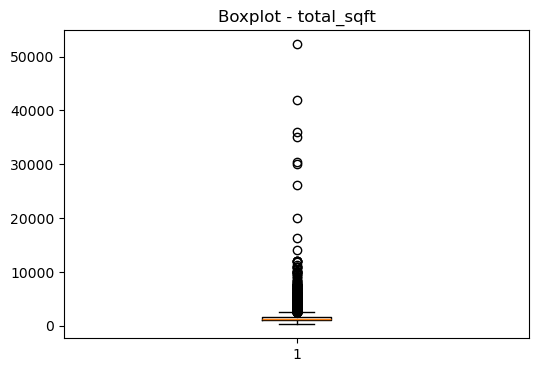

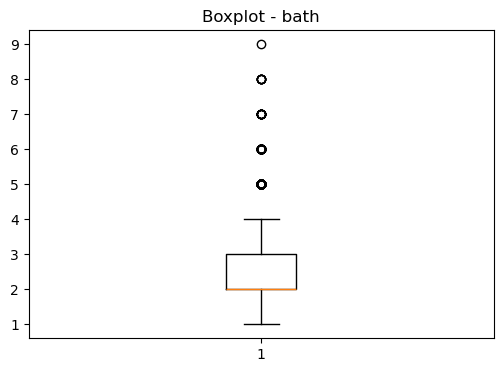

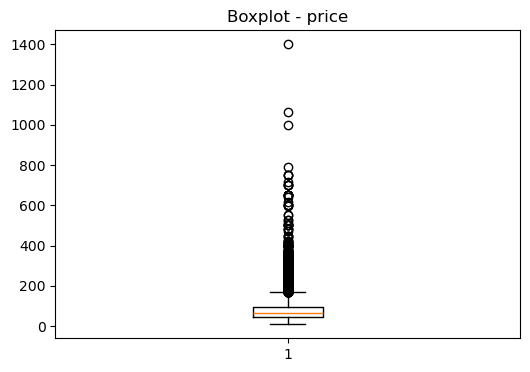

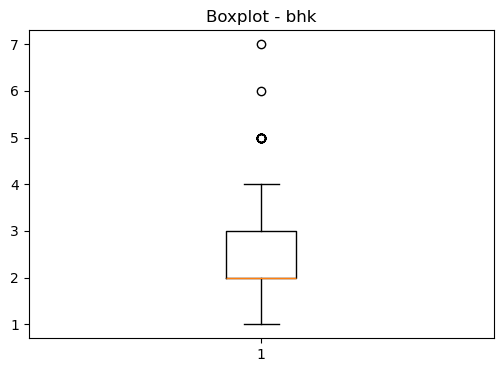

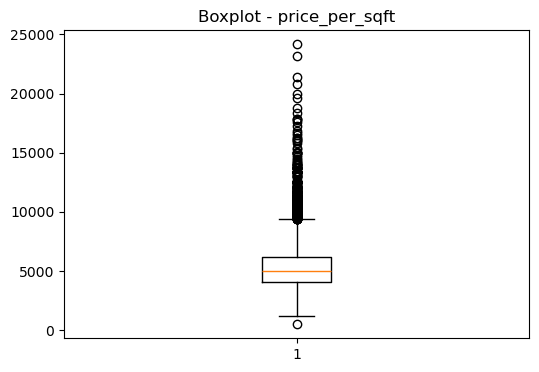

(10090, 7)


In [14]:
def remove_outliers_iqr(df, col):
    Q1 = np.percentile(df[col], 25.)
    Q3 = np.percentile(df[col], 75.)
    IQR = Q3 - Q1
    ll = Q1 - 1.5 * IQR
    ul = Q3 + 1.5 * IQR
    bad_indices = df[(df[col] > ul) | (df[col] < ll)].index.tolist()
    return df.drop(bad_indices, errors='ignore')

for col in ['total_sqft', 'bath', 'price', 'bhk', 'price_per_sqft']:
    plt.figure(figsize=(6,4))
    plt.boxplot(df6[col].dropna())
    plt.title(f'Boxplot - {col}')
    plt.show()
    df6 = remove_outliers_iqr(df6, col)

print(df6.shape)